[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SinaGhanbarii/gasmem/blob/main/notebooks/04_multicomponent.ipynb)

# 4 · Multicomponent feeds and published membranes

All four models handle any number of components. The membrane and feed presets below are taken
from published papers. `describe()` prints the conditions and the full reference for each one,
and `LITERATURE` holds the reference list.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: repository cloned into /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO = "https://github.com/SinaGhanbarii/gasmem.git"
if TOOLKIT is None and IN_COLAB:
    # opened from the "Open in Colab" badge: fetch the toolkit from GitHub
    import subprocess
    print("Downloading the toolkit from", REPO)
    if subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/gasmem"]).returncode:
        print("Download failed; looking in your Google Drive instead (approve the access request)")
        from google.colab import drive
        drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()               # makes the sliders work in Colab
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "your copy of the repository (git clone " + REPO + ").")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
import gasmem.plotting as gasmem_plot
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


In [2]:
for k, v in MEMBRANE_PRESETS.items():
    print(f"{k:48s}", {c: round(q, 3) for c, q in v.items()}, "GPU")
print()
print(describe("Cellulose acetate H2 recovery (Pan 1986)"))

Polaris CO2/N2 (Merkel 2010)                     {'CO2': 1000.0, 'N2': 20.0} GPU
Polaris pure-gas (MTR 2012)                      {'CO2': 1300.0, 'N2': 24.0, 'CH4': 80.0, 'H2': 110.0} GPU
Polyimide CO2/CH4, a=35 (Makaruk 2010)           {'CO2': 100.0, 'CH4': 2.857} GPU
Cellulose acetate H2 recovery (Pan 1986)         {'H2': 84.867, 'N2': 0.883, 'CH4': 0.849, 'Ar': 2.3} GPU
Cellulose acetate CO2/hydrocarbons (Pan 1986)    {'CO2': 40.043, 'CH4': 1.112, 'C2H6': 0.306, 'C3H8': 0.06} GPU
Cellulose acetate H2S/CO2 sour gas (Pan 1986)    {'H2S': 73.213, 'CO2': 73.213, 'CH4': 3.957, 'N2': 3.957, 'C2H6': 1.088} GPU
Polysulfone-like air (Coker 1998)                {'N2': 3.57, 'O2': 20.0, 'CO2': 60.0, 'H2O': 1000.0} GPU
Polysulfone-like H2/hydrocarbons (Coker 1998)    {'H2': 100.0, 'C2H4': 3.03, 'CH4': 2.86, 'C2H6': 2.0, 'C3H8': 1.89} GPU
Asymmetric hollow fibre air (Feng 1999)          {'O2': 9.198, 'N2': 1.703} GPU

Cellulose acetate H2 recovery (Pan 1986)
  Asymmetric cellulose acetate hollow

## Your own membrane from permeability data

Papers usually report **permeability** (Barrer). The modules need **permeance** (GPU), which
depends on the thickness of the selective layer: permeance [GPU] = permeability [Barrer] /
thickness [µm]. `Membrane.from_permeability` does the conversion, and the Robeson plot shows
where the material sits against the best known polymers.

Membrane('0.5 um layer': CO2=1356, CH4=67.18 GPU)
fraction of the 2008 upper-bound selectivity: 0.67


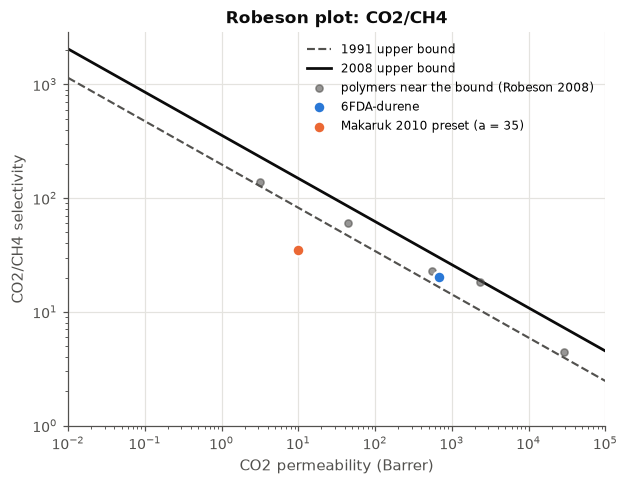

In [3]:
from gasmem.robeson import plot_upper_bound
# 6FDA-durene polyimide (Robeson 2008, Table 2): P(CO2) = 677.8 Barrer, CO2/CH4 = 20.18
mine = Membrane.from_permeability({"CO2": 677.8, "CH4": 677.8 / 20.18}, thickness_um=0.5)
print(mine)
print("fraction of the 2008 upper-bound selectivity:",
      round(distance_to_bound("CO2/CH4", 677.8, 20.18), 2))
plot_upper_bound("CO2/CH4", points={"6FDA-durene": (677.8, 20.18),
                                     "Makaruk 2010 preset (a = 35)": (100 * 0.1, 35)}); plt.show()

The Makaruk preset is plotted as if its selective layer were 0.1 µm thick, an assumption made
only to place it on this chart: 100 GPU then corresponds to 10 Barrer.

## Biogas upgrading at the conditions of Makaruk et al. (2010)

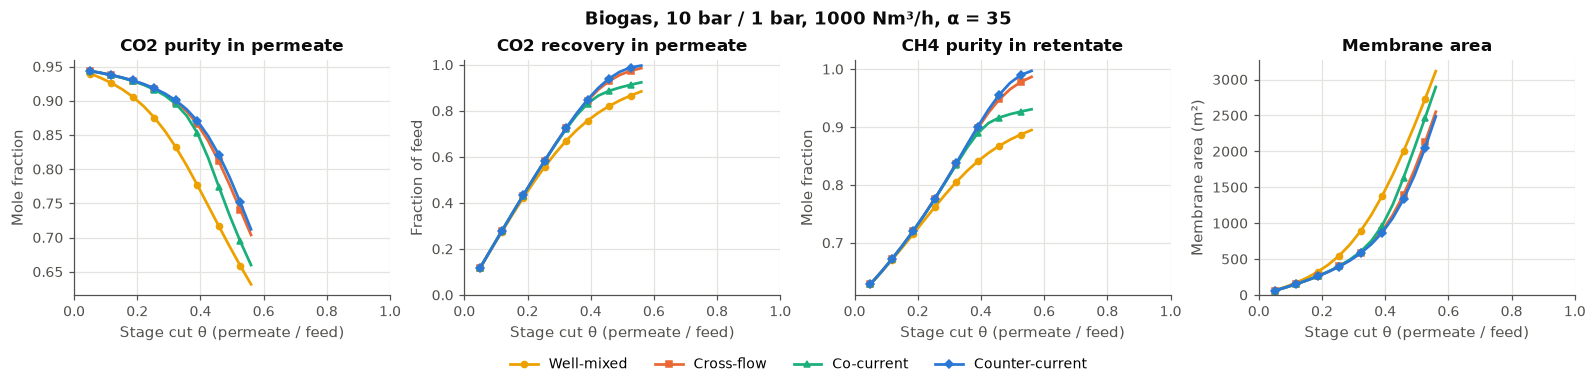

In [4]:
m = Membrane(MEMBRANE_PRESETS["Polyimide CO2/CH4, a=35 (Makaruk 2010)"])
F = nm3h_to_mols(1000)          # 1000 Nm3/h raw biogas, 10 bar, 60 % CH4
df = sweep_stage_cut(m, FEED_PRESETS["biogas, 60% CH4 (Makaruk 2010)"], p_high=10, p_low=1, feed_flow=F,
                     thetas=np.linspace(0.05, 0.56, 16))
plot_stage_cut_tradeoff(df, "CO2", slow="CH4",
                        title="Biogas, 10 bar / 1 bar, 1000 Nm³/h, α = 35"); plt.show()

For biogas the useful product is the **retentate**, which is methane-rich. Its purity climbs with
stage cut, but so does the methane lost to the permeate. This is the classic single-stage
dilemma, and it is why notebook 06 looks at multistage layouts.

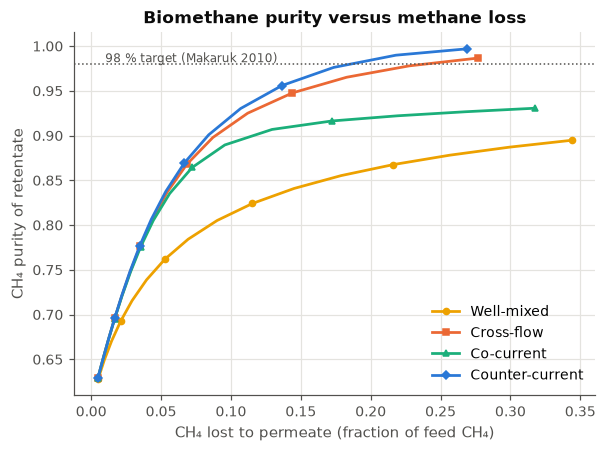

In [5]:
d = df.copy()
fig, ax = plt.subplots(figsize=(5.4, 4), constrained_layout=True)
for p in PATTERNS:
    s = d[d["pattern"] == p]
    ax.plot(s["recovery_perm_CH4"], s["x_ret_CH4"], color=COLORS[p], marker=MARKERS[p],
            markevery=3, markersize=4, label=LABELS[p])
ax.axhline(0.98, color="#52514e", lw=1, ls=":"); ax.text(0.01, 0.982, "98 % target (Makaruk 2010)", color="#52514e", fontsize=8)
ax.set_xlabel("CH₄ lost to permeate (fraction of feed CH₄)"); ax.set_ylabel("CH₄ purity of retentate")
ax.set_title("Biomethane purity versus methane loss"); ax.legend();

## Five components: hydrogen from a refinery purge (Coker et al. 1998)

With three or more components something new appears. A component of **intermediate**
permeability (here methane) can pass through a concentration maximum inside the module: the
fast gas leaves first and enriches it, then it is stripped in turn. Coker et al. point out that
this could be exploited by staging.

countercurrent: stage cut = 0.8500, area = 258.8 m2, p_h/p_l = 42.4/7.9 bar
  comp     feed  retent.    perm.  rec->perm
    H2   0.6500   0.0000   0.7647     1.0000
  C2H4   0.0250   0.0624   0.0184     0.6256
   CH4   0.2100   0.5490   0.1502     0.6079
  C2H6   0.0800   0.2676   0.0469     0.4983
  C3H8   0.0350   0.1210   0.0198     0.4814


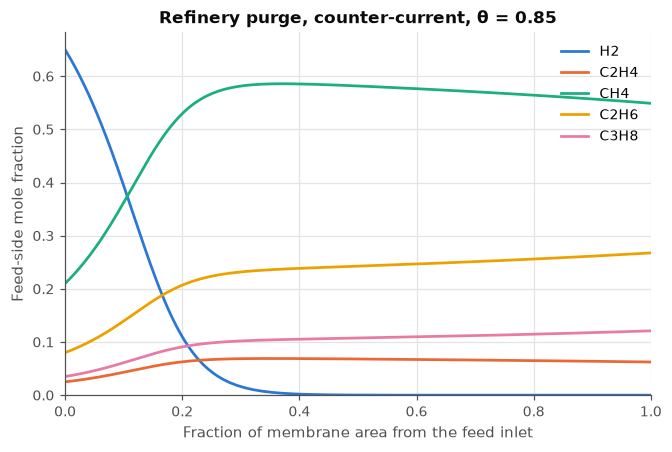

In [6]:
m = Membrane(MEMBRANE_PRESETS["Polysulfone-like H2/hydrocarbons (Coker 1998)"])
xf = FEED_PRESETS["refinery hydrotreater purge (Coker 1998)"]
r = countercurrent(m, xf, 0.85, 42.4, 7.9, nm3h_to_mols(283.2))
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
for i, c in enumerate(m.components):
    ax.plot(r.profile["area_fraction"], r.profile["x"][i], color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"][i], label=c)
ax.set(xlabel="Fraction of membrane area from the feed inlet", ylabel="Feed-side mole fraction",
       title="Refinery purge, counter-current, θ = 0.85", xlim=(0, 1), ylim=(0, None)); ax.legend();
print(r.summary())

## Interactive: any published preset, any pressures

In [7]:
def explore(membrane="Polaris CO2/N2 (Merkel 2010)", p_high=2.0, p_low=0.2, theta_max=0.8):
    m = Membrane(MEMBRANE_PRESETS[membrane])
    feed = PAIRINGS[membrane]
    xf = FEED_PRESETS[feed]
    fast = max(m.gpu, key=m.gpu.get)
    slow = max(xf, key=lambda c: xf[c] if c != fast else -1)
    display(Markdown(describe(membrane).replace("\n", "  \n")))
    df = sweep_stage_cut(m, xf, p_high, p_low, thetas=np.linspace(0.03, theta_max, 14))
    plot_stage_cut_tradeoff(df, fast, slow=slow, title=f"{membrane}  ·  {feed}"); plt.show()

w.interact_manual(explore,
                  membrane=w.Dropdown(options=list(MEMBRANE_PRESETS), value="Polaris CO2/N2 (Merkel 2010)"),
                  p_high=w.FloatSlider(value=2.0, min=1.0, max=80, step=0.5, description="p feed (bar)"),
                  p_low=w.FloatSlider(value=0.2, min=0.05, max=10, step=0.05, description="p perm (bar)"),
                  theta_max=w.FloatSlider(value=0.8, min=0.2, max=0.95, step=0.05, description="max θ"));

interactive(children=(Dropdown(description='membrane', options=('Polaris CO2/N2 (Merkel 2010)', 'Polaris pure-…

Press **Run Interact** after changing the inputs. Each preset uses the feed from its own paper. Multicomponent counter-current sweeps take a few seconds.